# Hacia un sistema de valuación masiva con BART para la vivienda de Bogotá y alrededores

## Contexto
Actualmente, en Colombia no existe la facilidad para acceder a datos oficiales sobre precios reales de venta de viviendas por parte del Estado, y cuando existe acceso, este por lo general es poco confiable debido a fenómenos como la subdeclaración fiscal (Lozano-Gracia and Anselin, 2012). Como señala Iban (2022), esta falta de información transaccional no es exclusiva del contexto colombiano y se replica en otros países en desarrollo como Turquía, de ahí que nazca el interés en el desarrollo de Sistemas de Valuación Masiva (MAS) utilizando precios ofrecidos (*asking prices*) recopilados a partir de portales web como FincaRaíz.

Los sistemas de valuación masiva en finca raíz son una forma que se suele utilizar en países con información inmobiliaria disponible para estimar mejor los precios; asimismo, estos sistemas tienen un efecto regulatorio en el comportamiento del mercado y permiten pasar de valuaciones subjetivas hechas por valuadores humanos que difieren entre sí (Lozano-Gracia and Anselin, 2012; Iban, 2022; Tapia et al., 2025). No obstante, en países con poco acceso a información sobre ventas reales, la creación de estos sistemas se complica sustancialmente (Lozano-Gracia and Anselin, 2012; Iban, 2022).

Bajo este marco, se plantea crear un prototipo de un sistema MAS para los precios pedidos en Bogotá y alrededores, con el fin de generar una forma sistemática de valuar los precios, contribuyendo así a la estabilización del mercado inmobiliario de la ciudad.

## Pregunta Problema
¿Qué factores de ubicación (localidad/municipio, estrato) y de características físicas (área, habitaciones, baños, antigüedad) se asocian con el precio pedido de la vivienda usada en Bogotá, Soacha, Chía y Zipaquirá y cuáles son los mejores para predecir el precio?

## Data
La población de interés consta de todas las viviendas de Bogotá y alrededores (Chía, Zipaquirá y Soacha); específicamente, la muestra recolectada abarca casas, apartamentos, apartaestudios, fincas y casas campestres, todas ellas extraídas del portal FincaRaíz mediante un scraper creado con la asistencia de inteligencia artificial. El conjunto inicial contiene 31.252 observaciones. No obstante, es necesario recalcar que la muestra extraída tiene una mayor representatividad por parte de inmuebles ubicados en la zona norte de la ciudad, lo cual podría constituir cierto sesgo en el análisis descriptivo y en la representatividad de la población.

La variable respuesta es `price_amount`, correspondiente al precio pedido del inmueble en pesos colombianos. Como predictores se consideran características físicas (área construida, habitaciones, baños, parqueaderos, piso, antigüedad y estado), de ubicación (estrato, municipio, localidad, barrio y coordenadas), de publicación y variables derivadas de las amenidades y de la distancia a *landmarks* positivos y negativos.

Como modelo principal se propone BART(Atr), propuesto por Cao et al. (2024), el cual se compara contra OLS, Random Forest, XGBoost, LightGBM y un predictor de la mediana. Antes del modelamiento se realiza una limpieza de la base, ya que presentaba serias inconsistencias, principalmente provenientes de cómo el portal maneja la información de entidades especiales, como proyectos que están en construcción, o de errores de digitación por parte de los vendedores.

## Hipótesis
Con base en la literatura consultada y a los datos extraídos, se plantean las siguientes hipótesis para esta investigación:

### 1. Dimensión física y atributos intrínsecos del inmueble
A medida que se incrementa la escala física de la vivienda (medida a través del área construida, el número de baños, la cantidad de dormitorios y las demás características físicas listadas), el precio pedido total de la propiedad aumenta, siendo la superficie construida el atributo estructural con mayor capacidad explicativa sobre el valor del inmueble (Lozano-Gracia and Anselin, 2012; Iban, 2022; Villada-Medina et al., 2023; Tapia et al., 2025).

### 2. Localización por zonas de alto valor
La ubicación geográfica en sectores del norte y oriente urbano (como las localidades de Usaquén y Chapinero en Bogotá) ejerce un impacto positivo sobre el precio pedido por metro cuadrado (Lozano-Gracia and Anselin, 2012; Loret de Mola et al., 2017; Tapia et al., 2025).

### 3. Proximidad a amenidades y desamenidades urbanas (*landmarks*)
La localización respecto a infraestructuras del entorno condiciona el valor del inmueble de forma considerable; mientras que la cercanía a amenidades positivas, tales como centros comerciales (Villada-Medina et al., 2023) y parques o espacios verdes (Loret de Mola et al., 2017; Tapia et al., 2025), genera un incremento en el precio por metro cuadrado, la lejanía física respecto a *landmarks* negativos o externalidades desfavorables (como el relleno sanitario Doña Juana, zonas industriales o centros penitenciarios) impacta positivamente la valoración de la vivienda al reducir el efecto desvalorizador de dichas fuentes de congestión, contaminación o deterioro (Lozano-Gracia and Anselin, 2012; Tapia et al., 2025).

### 4. Accesibilidad a transporte público
La proximidad a estaciones de transporte público constituye un factor determinante en el valor del inmueble (Chang, 2006; Tapia et al., 2025).

### 5. Estrato socioeconómico
Las viviendas localizadas en estratos socioeconómicos superiores presentan sistemáticamente un precio más elevado, actuando el estrato como una variable clave en el mercado inmobiliario colombiano (Lozano-Gracia and Anselin, 2012).

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from utils.geo import (
    CUNDINAMARCA_BBOX,
    count_outside_bogota,
    outside_bbox_mask,
)
from utils.map_graph import create_map
from utils.plotting import EDAPlotter
from utils.triple_plot import normality_report

In [2]:
df = pd.read_csv("../data/fincaraiz_venta_bogota_20260803.csv")

## Variable dictionary

| Variable | Unit | Description |
|---|---|---|
| `listing_id` | id | Unique identifier of the listing on FincaRaíz. |
| `operation` | category | Transaction advertised: `venta` (sale) or `arriendo` (rent). |
| `property_type` | category | Class of property: `apartamento`, `casa`, `oficina`, `bodega`, `local`, `lote`, and similar. |
| `price_amount` | COP | Asking price published in the listing. |
| `price_currency` | category | Currency the asking price is quoted in. |
| `admin_fee` | COP / month | Monthly building administration fee (*administración*). |
| `total_monthly_cost` | COP / month | Rent plus administration fee; defined for rental listings. |
| `price_per_m2` | COP / m² | Asking price divided by built area. |
| `area_built_m2` | m² | Constructed area of the property. |
| `area_private_m2` | m² | Private interior area of the unit. |
| `bedrooms` | count | Number of bedrooms. |
| `bathrooms` | count | Number of bathrooms. |
| `parking_spaces` | count | Number of parking spaces included with the property. |
| `stratum` | ordinal 1–6 | Colombian socio-economic stratum assigned to the address. |
| `floor` | floor number | Floor of the building on which the unit sits. |
| `floors_total` | count | Number of floors in the building. |
| `age_bracket_code` | ordinal 0–5 | Age of the property as a bracket: 0 brand new, 1 under 1 year, 2 = 1–8, 3 = 9–15, 4 = 16–30, 5 over 30 years. |
| `age_bracket_label` | category | Spanish text label of the age bracket. |
| `construction_state` | category | Condition declared in the listing: `Usado`, `Excelente estado`, `En construcción`, and similar. |
| `city` | name | Municipality where the property is located. |
| `locality` | category | Bogotá *localidad* containing the property. |
| `neighborhood` | name | Neighbourhood (*barrio*) of the property. |
| `address_text` | text | Street address as published in the listing. |
| `latitude` | degrees (WGS84) | Latitude of the property's map location. |
| `longitude` | degrees (WGS84) | Longitude of the property's map location. |
| `amenities` | list (`\|`-separated) | Amenities and features attributed to the property or its building. |
| `agency_name` | name | Real-estate agency publishing the listing. |
| `publisher_type` | category | Kind of publisher: `inmobiliaria` (agency) or `desarrollador` (developer). |
| `published_at` | date (YYYY-MM-DD) | Date the listing was first published. |
| `updated_at` | date (YYYY-MM-DD) | Date the listing was last updated. |
| `source_url` | URL | Web address of the listing. |


# Basic descriptive statistics

In [3]:
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# Run describe again
df.describe()

,listing_id,price_amount,admin_fee,total_monthly_cost,price_per_m2,area_built_m2,area_private_m2,bedrooms,bathrooms,parking_spaces,stratum,floor,floors_total,age_bracket_code,latitude,longitude
count,31252.00,31252.00,17641.00,0.00,25206.00,25206.00,23129.00,31252.00,31252.00,20470.00,30658.00,15469.00,31252.00,30490.00,31252.00,31252.00
mean,180871972.11,3644250869.26,4528528.89,NaN,17804385.75,3125.00,1311.98,2.71,2.72,2.61,5.87,5.13,1.00,3.46,4.69,-74.06
std,46119900.68,96776331244.01,71313162.52,NaN,288143681.95,428453.68,104232.03,2.73,2.21,4.04,13.27,19.12,4.69,1.42,0.20,1.07
min,1277484.00,0.00,1.00,NaN,0.00,0.10,0.00,-1.00,0.00,-2.00,1.00,1.00,0.00,0.00,-0.04,-105.35
25%,192663856.50,440000000.00,300000.00,NaN,4470827.36,62.00,60.00,1.00,1.00,1.00,3.00,2.00,0.00,2.00,4.65,-74.09
50%,193513452.00,860000000.00,649000.00,NaN,6045240.00,134.00,130.00,3.00,2.00,2.00,4.00,3.00,0.00,4.00,4.69,-74.07
75%,193808646.25,1790000000.00,1200000.00,NaN,8199852.41,300.00,270.00,4.00,4.00,3.00,5.00,5.00,1.00,5.00,4.72,-74.05
max,194064832.00,13789000000000.00,2147483647.00,NaN,15151515151.52,68000000.00,14390000.00,68.00,80.00,127.00,110.00,902.00,403.00,5.00,22.73,0.00


Los estadísticos descriptivos iniciales muestran señales claras de problemas de calidad y valores extremos. Por ejemplo, el precio presenta una media cercana a 3,64 mil millones de pesos frente a una mediana de 860 millones, mientras que el máximo alcanza aproximadamente 13,8 billones de pesos. La gran diferencia entre media y mediana evidencia una fuerte asimetría hacia la derecha y la presencia de outliers.

Algo similar ocurre con variables de área: area_built_m2 tiene una mediana de 134 m², pero un máximo de 68 millones de m². También aparecen valores lógicamente cuestionables como −1 habitaciones, estratos 100 y 110 y pisos superiores a 900. Por tanto, estos descriptivos deben entenderse como una caracterización de la base antes de la limpieza, no como valores representativos definitivos del mercado.

In [4]:
df.loc[df["floor"].idxmax()]

listing_id                                                    192418470
operation                                                         venta
property_type                                                   oficina
price_amount                                               250000000.00
price_currency                                                      COP
admin_fee                                                     520000.00
total_monthly_cost                                                  NaN
price_per_m2                                                 3846153.85
area_built_m2                                                     65.00
area_private_m2                                                   65.00
bedrooms                                                              0
bathrooms                                                             0
parking_spaces                                                      NaN
stratum                                                         

<Axes: title={'center': 'Distribution of Stratum'}, xlabel='stratum'>

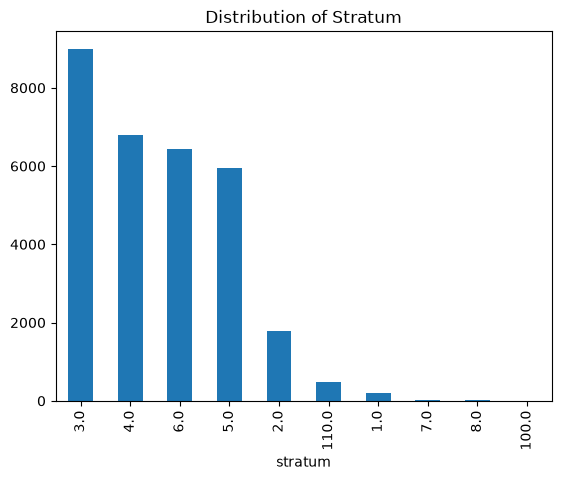

In [5]:
df["stratum"].value_counts().plot(kind="bar", title="Distribution of Stratum")

In [6]:
df["stratum"].value_counts()

stratum
3.00      8997
4.00      6785
6.00      6425
5.00      5947
2.00      1781
110.00     481
1.00       190
7.00        29
8.00        17
100.00       6
Name: count, dtype: int64

In [7]:
df["floor"].value_counts()  # when a floor is like nxx, the n is the floor
# number, and the xx is the apartment number. So, 3xx means floor 3.

floor
1.00      2987
2.00      2884
3.00      2497
4.00      1895
5.00      1579
6.00       866
7.00       584
8.00       383
18.00      307
9.00       247
10.00      218
12.00      216
11.00      190
16.00      108
13.00      108
14.00      101
15.00       99
17.00       46
20.00       23
19.00       22
21.00       14
22.00       14
27.00        9
24.00        8
25.00        6
23.00        6
29.00        6
28.00        5
26.00        4
32.00        3
30.00        3
101.00       3
301.00       3
608.00       2
44.00        2
403.00       2
402.00       2
303.00       2
102.00       2
203.00       2
502.00       2
211.00       1
902.00       1
501.00       1
801.00       1
505.00       1
404.00       1
701.00       1
601.00       1
35.00        1
Name: count, dtype: int64

In [8]:
(533 / df.shape[0]) * 100

1.7054908485856903

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31252 entries, 0 to 31251
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   listing_id          31252 non-null  int64  
 1   operation           31252 non-null  str    
 2   property_type       31252 non-null  str    
 3   price_amount        31252 non-null  float64
 4   price_currency      31252 non-null  str    
 5   admin_fee           17641 non-null  float64
 6   total_monthly_cost  0 non-null      float64
 7   price_per_m2        25206 non-null  float64
 8   area_built_m2       25206 non-null  float64
 9   area_private_m2     23129 non-null  float64
 10  bedrooms            31252 non-null  int64  
 11  bathrooms           31252 non-null  int64  
 12  parking_spaces      20470 non-null  float64
 13  stratum             30658 non-null  float64
 14  floor               15469 non-null  float64
 15  floors_total        31252 non-null  int64  
 16  age_bracket_cod

La base contiene **31.252 observaciones y 31 variables**, incluyendo variables numéricas y categóricas. Algunas columnas presentan valores faltantes, por lo que será necesario revisarlos durante la limpieza de los datos.

# Look for inconsistent coordinates

In [10]:
geo_check = count_outside_bogota(df.latitude, df.longitude)
print(geo_check)

outside = outside_bbox_mask(df.latitude, df.longitude)
df.loc[outside, ["city", "latitude", "longitude"]]

{'total': 31252, 'inside': 31228, 'outside': 24, 'missing': 0, 'pct_outside': 0.08, 'bbox': BBox(lat_min=3.65, lat_max=5.85, lon_min=-75.0, lon_max=-73.0)}


,city,latitude,longitude
173,Cali,3.44,-76.51
782,Cali,3.44,-76.51
1547,Bucaramanga,7.15,-73.13
2136,Bogotá,20.97,-101.28
2210,NaN,0.00,0.00
2247,Medellín,6.30,-75.57
2305,NaN,0.00,0.00
2550,Cali,3.44,-76.51
2671,Bucaramanga,7.12,-73.12
2889,Bogotá,22.73,-105.35


De las 31.252 observaciones, 24 se encuentran fuera del rango geográfico utilizado como referencia, aproximadamente el **0,08 %** de la base. Entre ellas aparecen registros atribuidos a Bogotá con coordenadas incompatibles con la ciudad, coordenadas (0,0) y ubicaciones correspondientes a otras ciudades. Esto evidencia inconsistencias geográficas puntuales que deberán revisarse durante la etapa de limpieza antes de utilizar latitud y longitud como predictores.

# First Plots

In [11]:
categorical_columns = {
    "operation",
    "property_type",
    "price_currency",
    "stratum",
    "age_bracket_code",
    "age_bracket_label",
    "construction_state",
    "city",
    "locality",
    "neighborhood",
    "amenities",
    "agency_name",
    "publisher_type",
}

continuous_columns = {
    "price_amount",
    "admin_fee",
    "total_monthly_cost",
    "price_per_m2",
    "area_built_m2",
    "area_private_m2",
    "latitude",
    "longitude",
}

discrete_columns = {
    "bedrooms",
    "bathrooms",
    "parking_spaces",
    "floor",
    "floors_total",
}

# In none of the three: listing_id (identifier), address_text and
# source_url (free text), published_at and updated_at (dates).

### Categorical columns

d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\plotting.py:5779: UserWarning: Column 'stratum' is numeric but has only 10 distinct value(s), so it is treated as categorical. Override with treat_as={'stratum': 'numeric'} or the constructor's as_numeric=['stratum'].
  kind_x = self.resolve_kind(xs, treat.get(str(xs.name)))
D:\Temp\ipykernel_22848\84319408.py:4: UserWarning: barplot('stratum'): dropped 594 row(s) (1.9%) with nulls in stratum; n = 30,658 remain.
  plotter.barplot(
d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\plotting.py:1542: UserWarning: 10 levels exceed the 8-colour categorical palette; colours will repeat. Consider top_n=... or faceting.
  colors = self._palette_colors(len(cached) + len(missing), palette)
D:\Temp\ipykernel_22848\84319408.py:4: UserWarning: barplot('amenities'): dropped 2,875 row(s) (9.2%) with nulls in amenities; n = 28,377 remain.
  plotter.barplot(
D:\Temp\ipykernel_22848\84319408.py:4: UserWarni

Error plotting amenities: 'amenities' has 23142 levels, above the max_levels_error limit of 50. Pass top_n=... to keep only the most frequent levels.


D:\Temp\ipykernel_22848\84319408.py:4: UserWarning: barplot('age_bracket_label'): dropped 762 row(s) (2.4%) with nulls in age_bracket_label; n = 30,490 remain.
  plotter.barplot(
D:\Temp\ipykernel_22848\84319408.py:4: UserWarning: barplot('construction_state'): dropped 1,558 row(s) (5.0%) with nulls in construction_state; n = 29,694 remain.
  plotter.barplot(
D:\Temp\ipykernel_22848\84319408.py:4: UserWarning: barplot('locality'): dropped 4,623 row(s) (14.8%) with nulls in locality; n = 26,629 remain.
  plotter.barplot(
d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\plotting.py:5779: UserWarning: Column 'age_bracket_code' is numeric but has only 6 distinct value(s), so it is treated as categorical. Override with treat_as={'age_bracket_code': 'numeric'} or the constructor's as_numeric=['age_bracket_code'].
  kind_x = self.resolve_kind(xs, treat.get(str(xs.name)))
D:\Temp\ipykernel_22848\84319408.py:4: UserWarning: barplot('age_bracket_code'): dropped 762 row(s

Error plotting neighborhood: 'neighborhood' has 1272 levels, above the max_levels_error limit of 50. Pass top_n=... to keep only the most frequent levels.
Error plotting agency_name: 'agency_name' has 1253 levels, above the max_levels_error limit of 50. Pass top_n=... to keep only the most frequent levels.
Error plotting city: 'city' has 76 levels, above the max_levels_error limit of 50. Pass top_n=... to keep only the most frequent levels.


D:\Temp\ipykernel_22848\84319408.py:4: UserWarning: barplot('agency_name'): dropped 1,115 row(s) (3.6%) with nulls in agency_name; n = 30,137 remain.
  plotter.barplot(


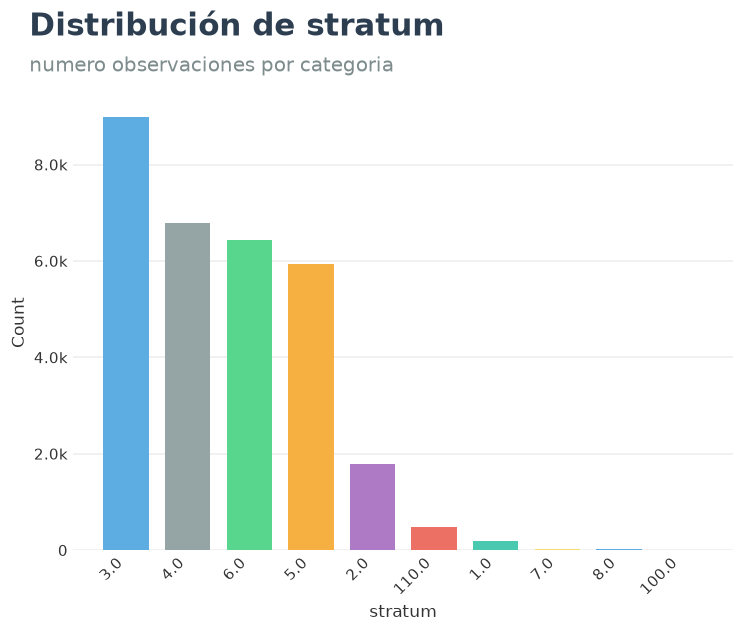

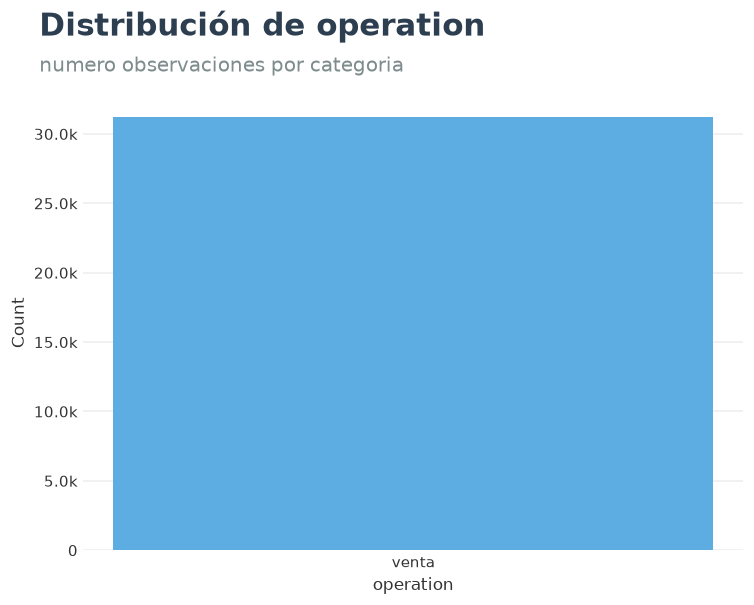

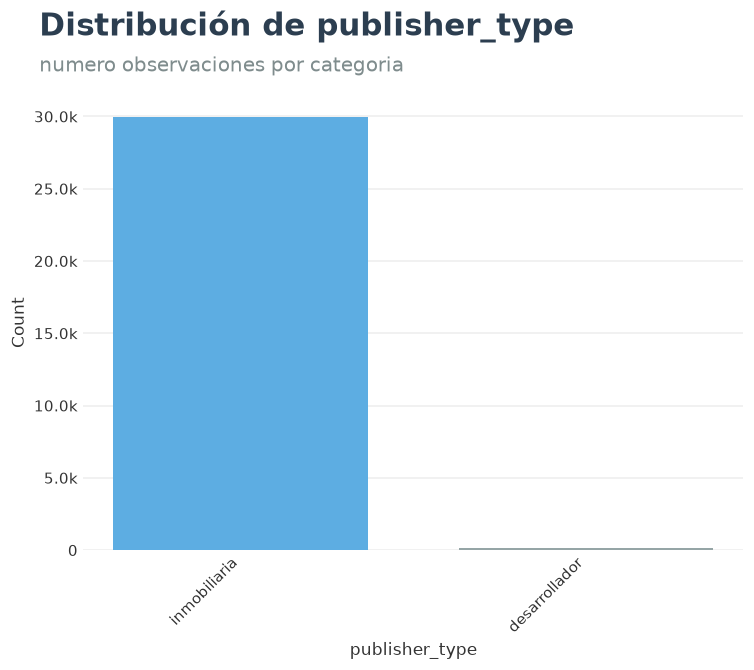

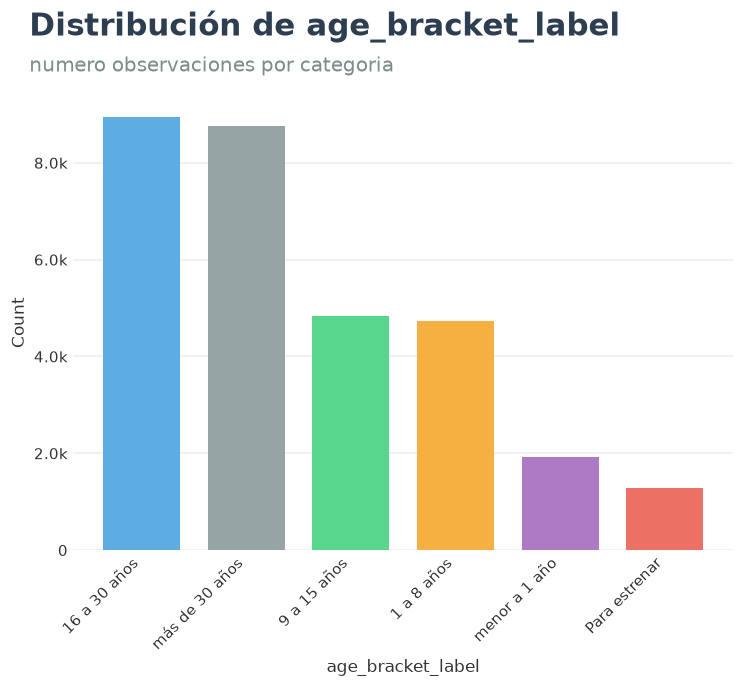

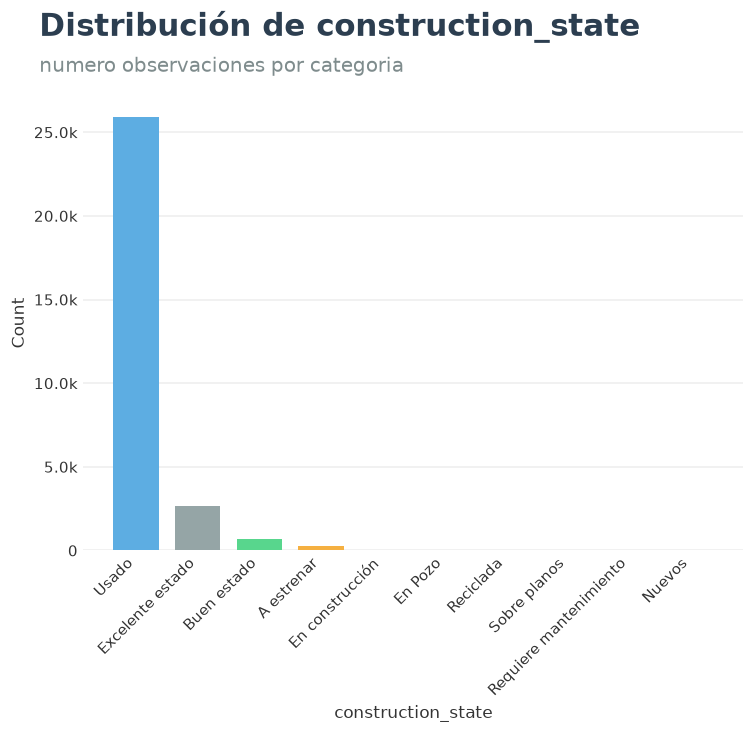

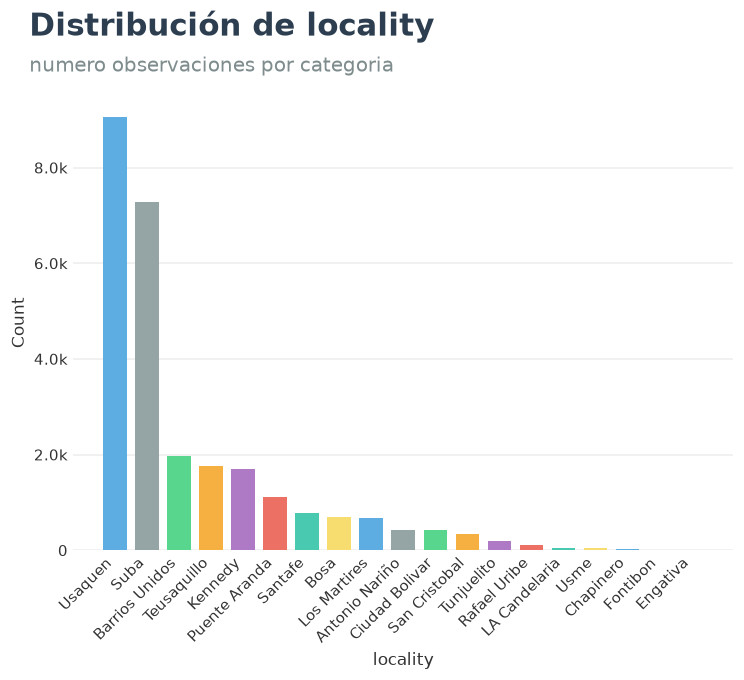

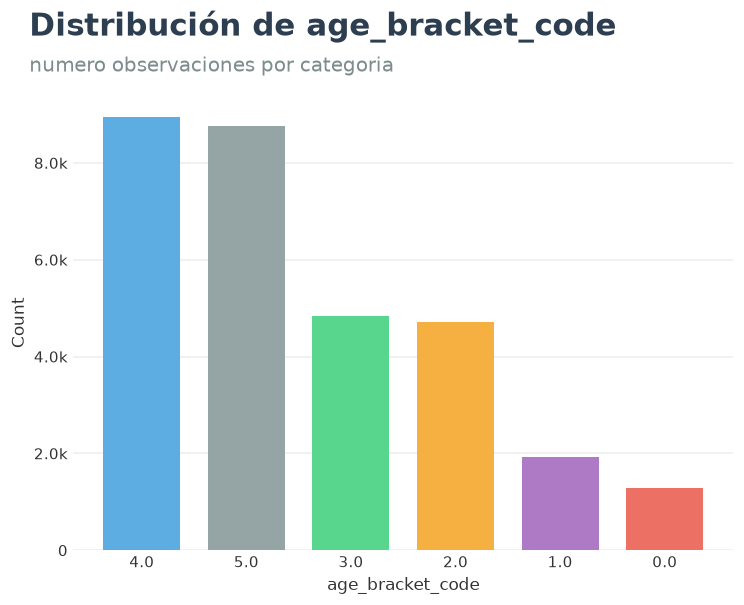

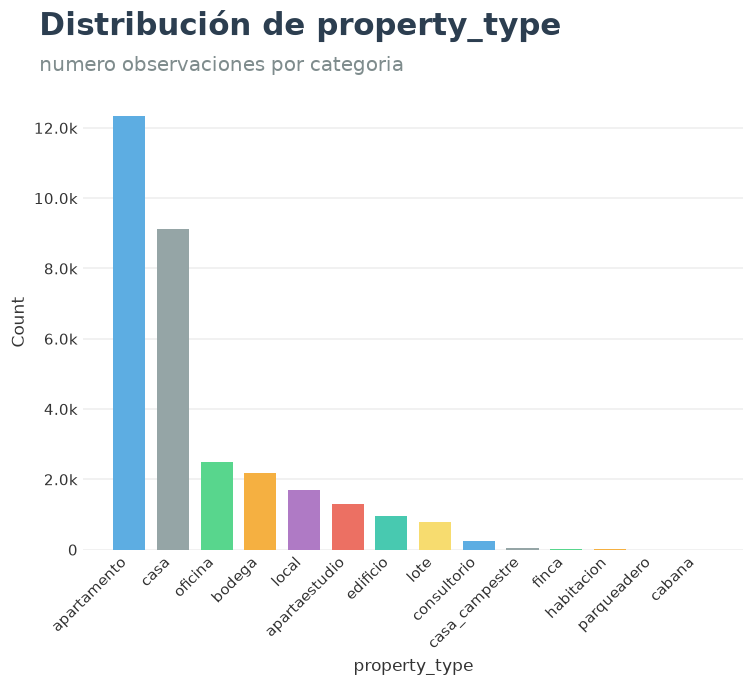

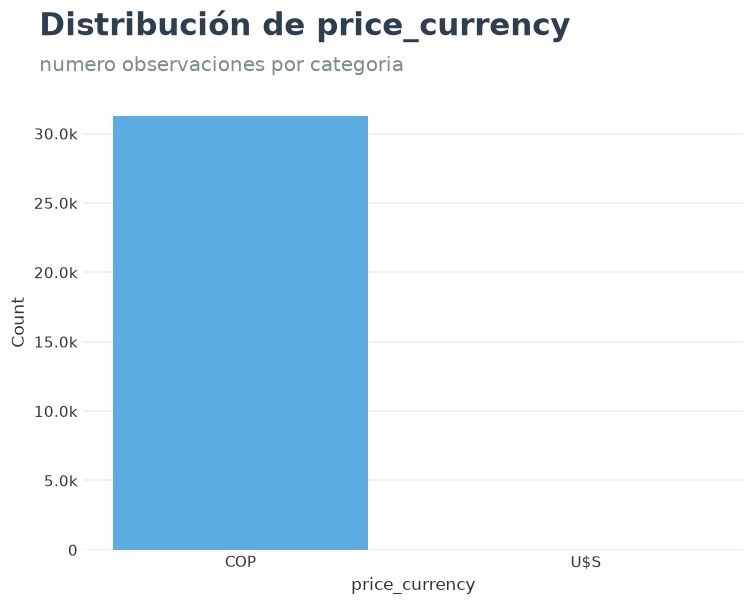

In [12]:
plotter = EDAPlotter(df)
for col in categorical_columns:
    try:
        plotter.barplot(
            x=col,
            title=f"Distribución de {col}",
            subtitle="numero observaciones por categoria",
        )
    except Exception as e:
        print(f"Error plotting {col}: {e}")

Las distribuciones de las variables categóricas muestran que la base presenta una composición desigual entre varias de sus categorías.

Todos los registros corresponden a inmuebles en venta y prácticamente todos los precios se encuentran expresados en pesos colombianos (COP), lo cual es coherente con el alcance del conjunto de datos analizado.

En `property_type`, los apartamentos y las casas concentran la mayor parte de las observaciones, mientras que categorías como oficinas, bodegas, locales, lotes y casas campestres tienen una representación considerablemente menor.

Para `stratum`, la mayor concentración se encuentra en los estratos 3, 4, 5 y 6. Sin embargo, también aparecen valores como 7, 8, 100 y 110, que no corresponden al rango habitual de estratificación socioeconómica y constituyen inconsistencias.

En cuanto a la antigüedad, predominan los inmuebles con más de 15 años y entre 16 y 30 años, aunque también existe representación de construcciones más recientes. De forma similar, la variable `construction_state` está fuertemente concentrada en la categoría Usado, mientras que las demás categorías poseen una frecuencia considerablemente menor.

La distribución por `locality` también es desigual, con una mayor presencia de inmuebles en localidades como Usaquén y Suba, seguidas por otras localidades con una cantidad considerablemente menor de registros.

Finalmente, algunas variables como `amenities`, `neighborhood` y `agency_name` presentan una cantidad muy elevada de categorías, lo que dificulta su análisis directo mediante gráficos de barras.

In [13]:
df.shape

(31252, 31)

### Discrete variables

d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\plotting.py:5614: UserWarning: x='floor' is continuous numeric; counting its raw values rarely reads well. Consider histplot, or bin it first.
  cat, value, hue_extra, orient = self._resolve_bar_axes(
D:\Temp\ipykernel_22848\2843218161.py:3: UserWarning: barplot('floor'): dropped 15,783 row(s) (50.5%) with nulls in floor; n = 15,469 remain.
  plotter.barplot(
d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\plotting.py:5635: UserWarning: 'floor' has 50 levels, which will be hard to read. Consider top_n=... to keep only the most frequent ones.
  work[cat_name] = self._limit_levels(work[cat_name], top_n)
d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\plotting.py:5614: UserWarning: x='bedrooms' is continuous numeric; counting its raw values rarely reads well. Consider histplot, or bin it first.
  cat, value, hue_extra, orient = self._resolve_bar_axes(
d:\Externado\

Error plotting parking_spaces: 'parking_spaces' has 54 levels, above the max_levels_error limit of 50. Pass top_n=... to keep only the most frequent levels.


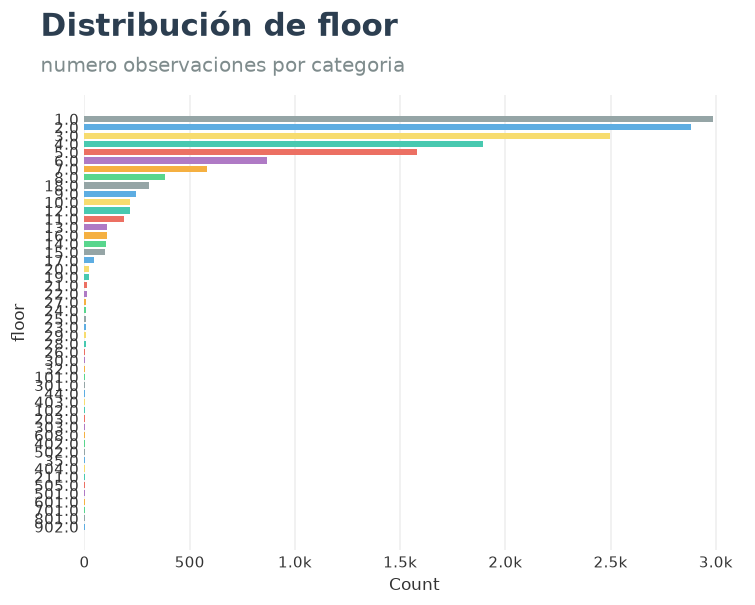

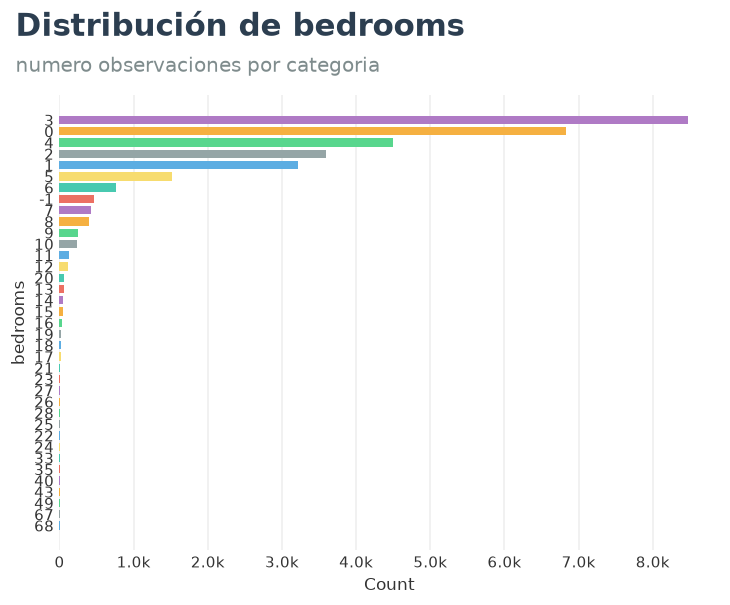

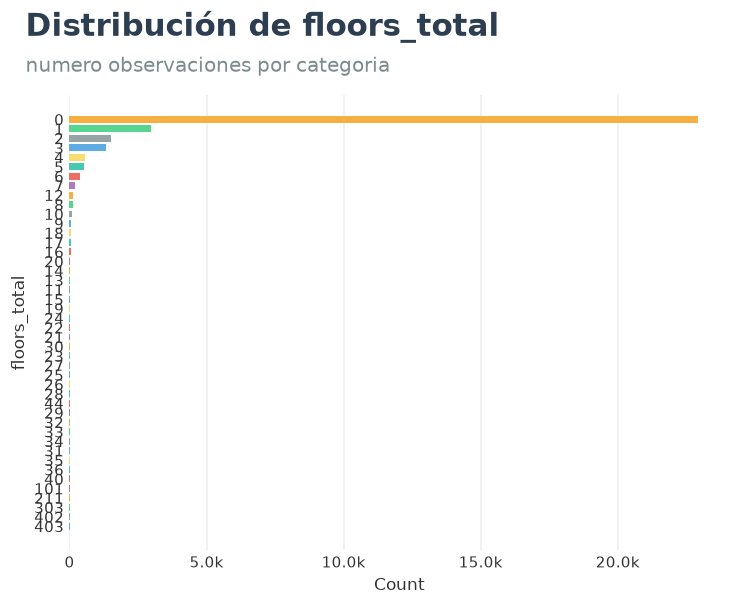

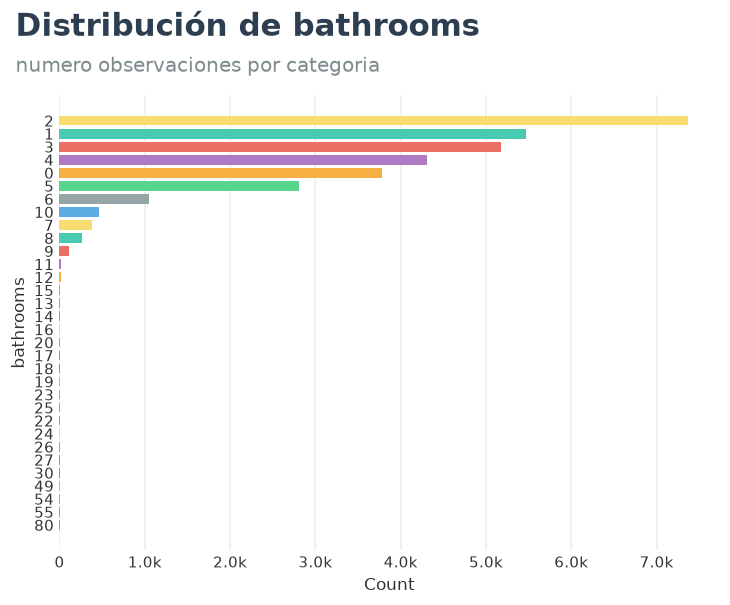

In [14]:
for col in discrete_columns:
    try:
        plotter.barplot(
            y=col,
            title=f"Distribución de {col}",
            subtitle="numero observaciones por categoria",
            rotate_xticks=90,
            orientation="horizontal",
        )
    except Exception as e:
        print(f"Error plotting {col}: {e}")

En `bedrooms`, la mayor frecuencia corresponde a inmuebles con 3 habitaciones, seguida por 0, 4, 2 y 1 habitación. Sin embargo, también aparecen valores negativos y cantidades muy elevadas de habitaciones, lo que evidencia posibles errores o registros atípicos.

En `bathrooms`, predominan los inmuebles con 2 baños, seguidos por aquellos con 1, 3 y 4 baños. También se observan valores considerablemente altos.

La variable `floor` se concentra principalmente entre los primeros pisos, pero presenta valores como 101, 301, 403, 608 y 902. Estos valores podrían corresponder a una codificación diferente al número real de piso y, por tanto, no deben interpretarse directamente como alturas del inmueble. Además, aproximadamente el **50,5 % de los registros de esta variable son valores faltantes**.

En `floors_total` existe una concentración particularmente alta en el valor 0, además de algunos valores extremos como 101, 303, 402 y 403. Esto sugiere que el valor 0 podría estar representando ausencia de información.

Finalmente, `parking_spaces` presenta aproximadamente un **34,5 % de valores faltantes** y más de 50 valores diferentes, razón por la cual su distribución no pudo representarse adecuadamente mediante el gráfico de barras utilizado.

## Continuous variables

### Using log scale

findfont: Failed to find font weight medium, now using 400.


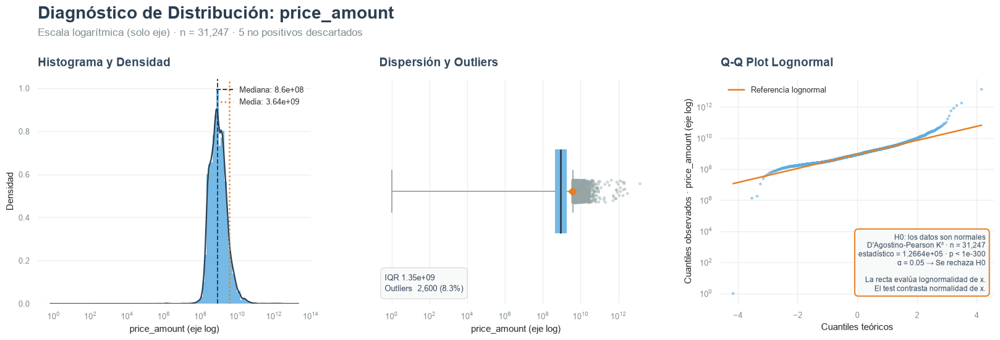

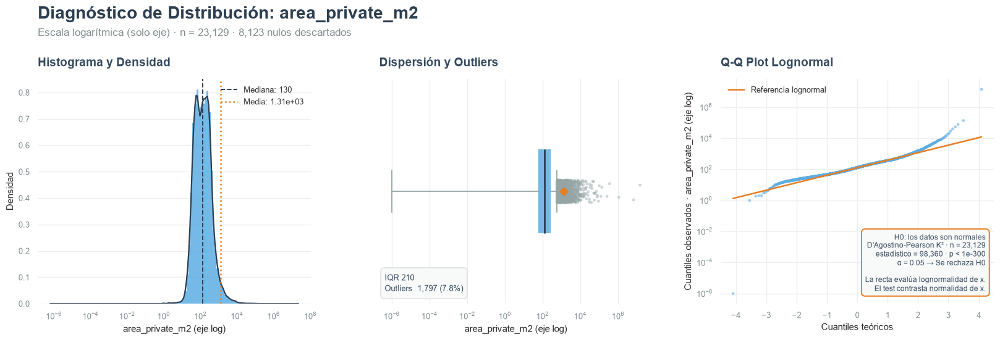

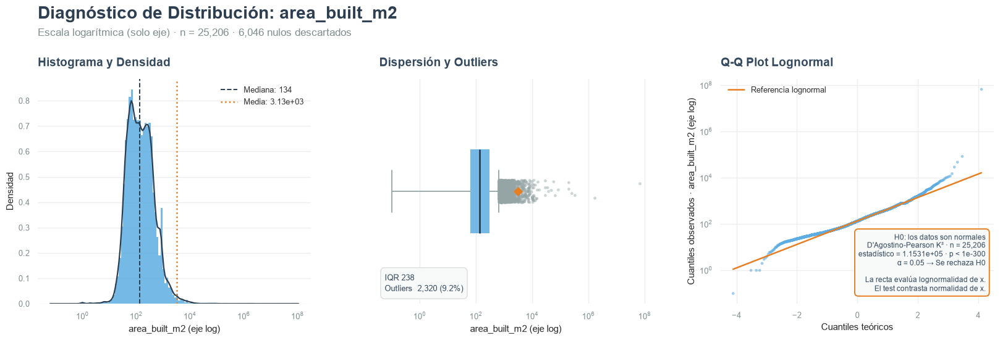

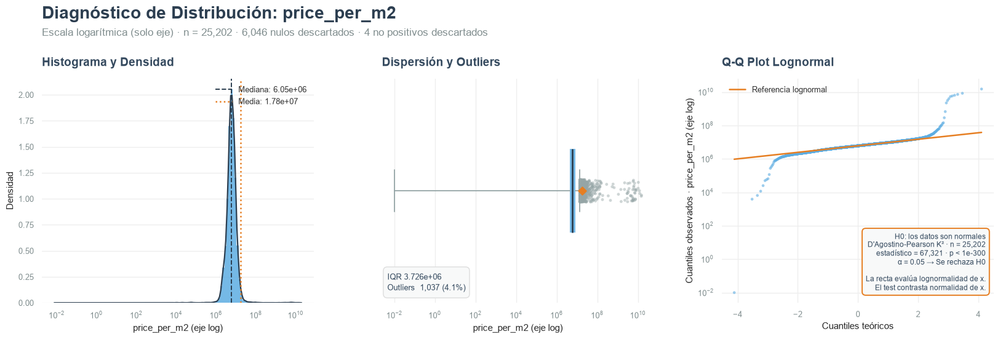

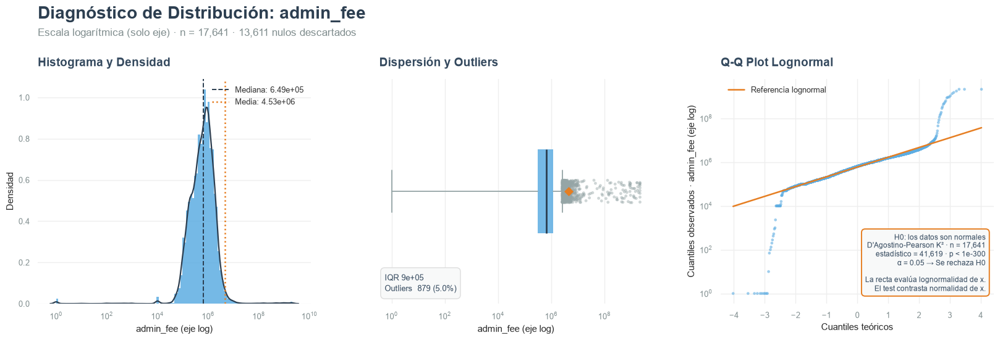

In [15]:
for col in continuous_columns:
    if col in ["latitude", "longitude", "total_monthly_cost"]:
        continue
    normality_report(
        df, col, log_scale=True, kde=True, test="auto", neg_strategy="drop"
    )

La representación de las variables continuas en escala logarítmica permite visualizar con mayor claridad distribuciones que en su escala original se encuentran fuertemente concentradas hacia los valores bajos y presentan colas derechas muy extensas.

Variables como `price_amount`, `area_built_m2`, `area_private_m2`, `price_per_m2` y `admin_fee` presentan una marcada asimetría positiva y observaciones extremas. Al utilizar un eje logarítmico, estos valores dejan de dominar completamente la visualización y se puede observar con mayor detalle la concentración de la mayoría de los registros.

### Using Log Transformation 

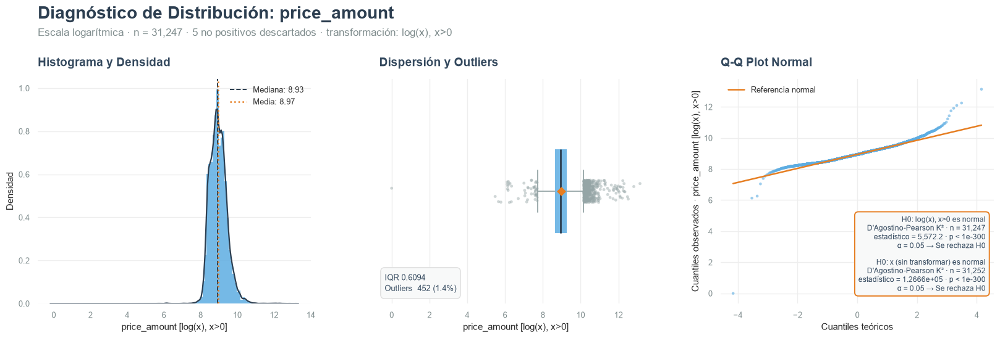

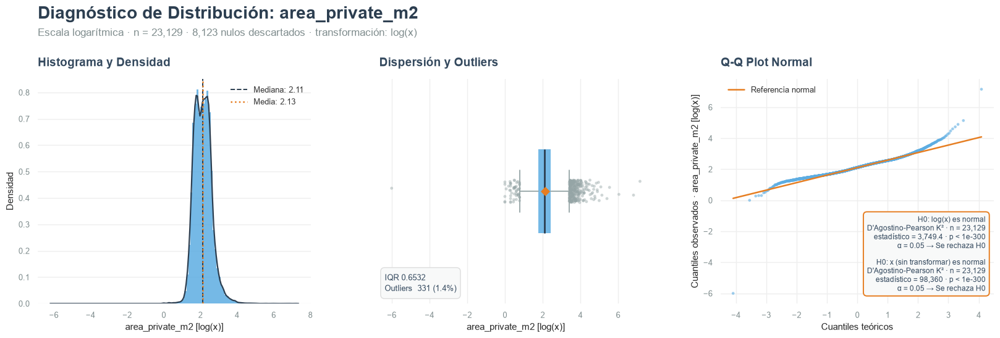

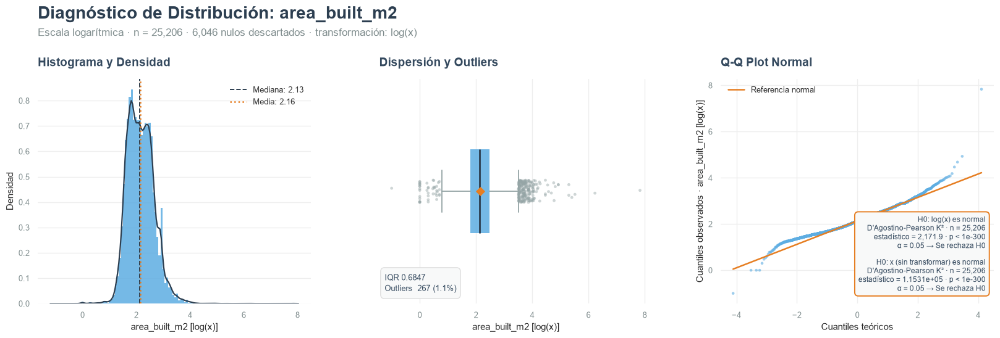

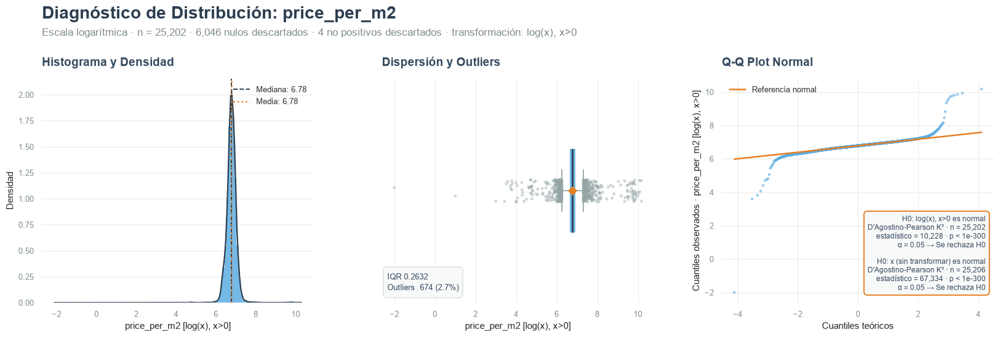

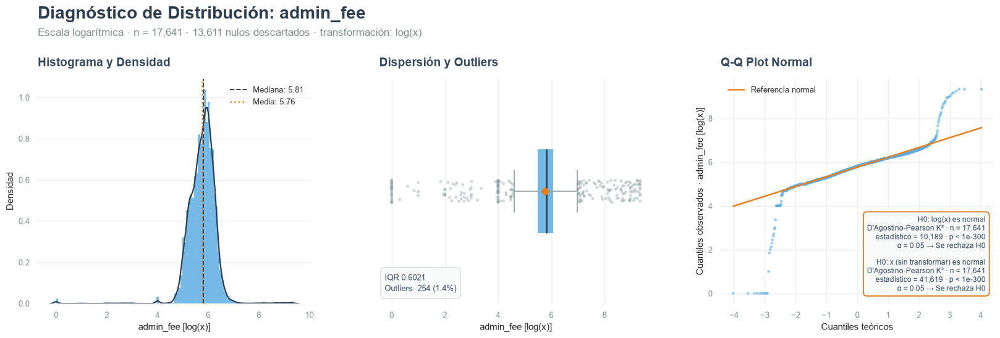

In [16]:
for col in continuous_columns:
    if col in ["latitude", "longitude", "total_monthly_cost"]:
        continue
    normality_report(
        df,
        col,
        log_transformation=True,
        kde=True,
        test="auto",
        neg_strategy="drop",
    )

Al aplicar una transformación logarítmica a las variables continuas se reduce considerablemente la asimetría positiva observada en la escala original. Esto es especialmente evidente en `price_amount`, `area_built_m2` y `area_private_m2`, donde la media y la mediana se aproximan y la mayor parte de las observaciones se concentra de forma más equilibrada alrededor del centro de la distribución.

No obstante, los gráficos Q–Q muestran desviaciones en las colas y las pruebas de normalidad continúan rechazando la hipótesis de normalidad para las variables transformadas. Por tanto, la transformación logarítmica mejora la simetría de las distribuciones, pero no permite afirmar que estas sean normales.

### Without transform

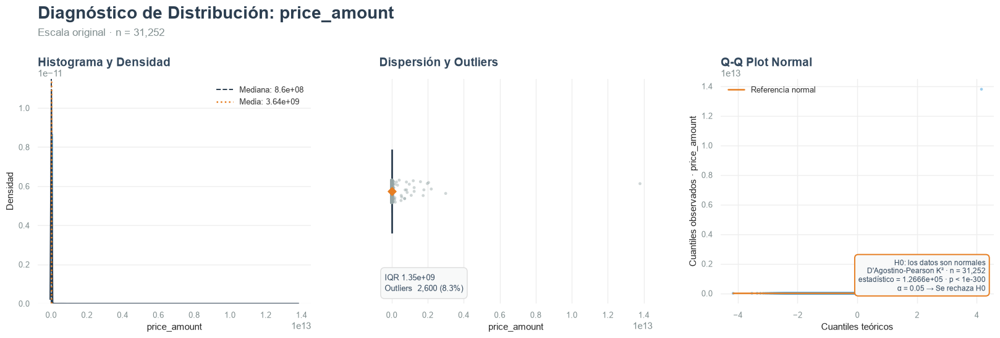

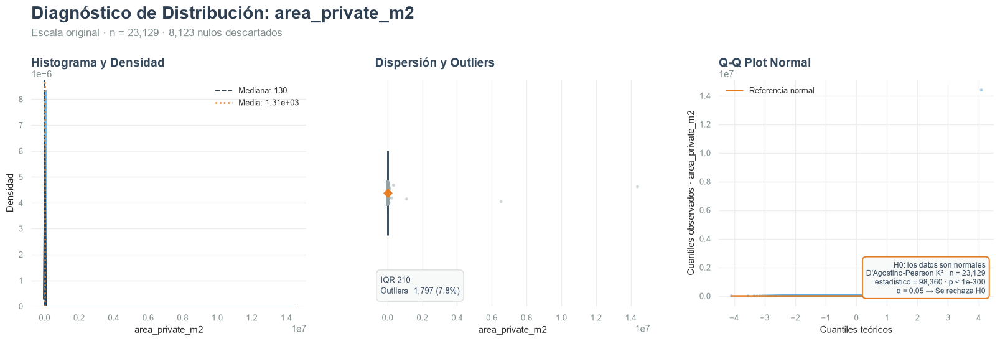

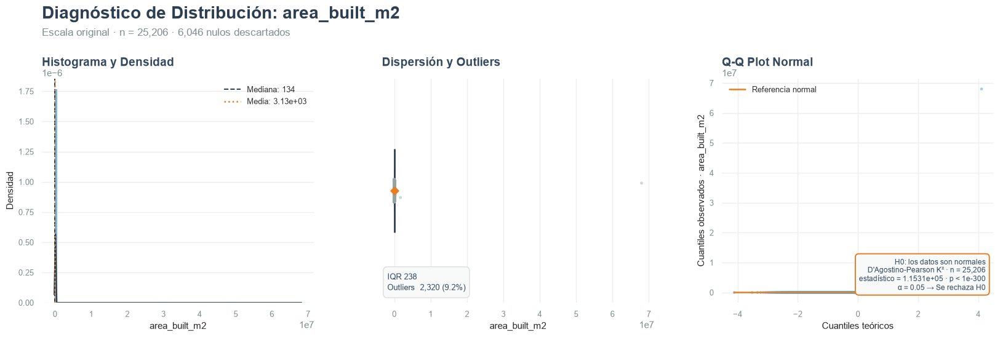

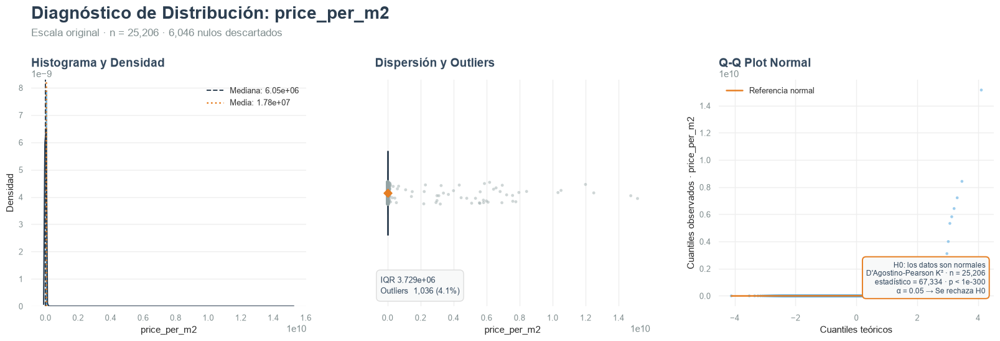

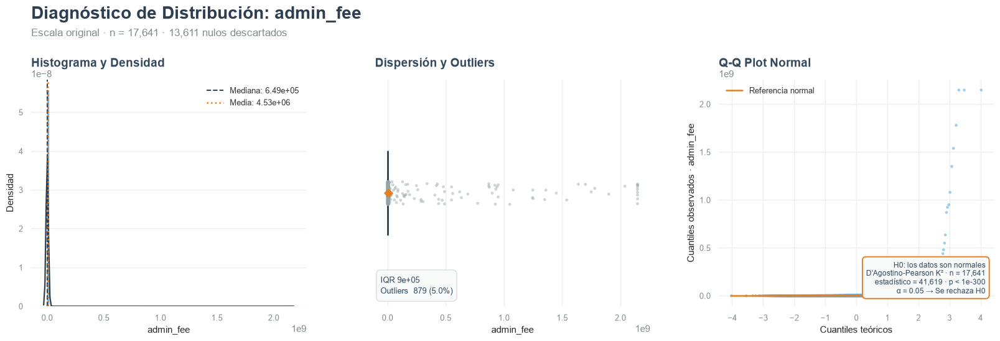

In [17]:
for col in continuous_columns:
    if col in ["latitude", "longitude", "total_monthly_cost"]:
        continue
    normality_report(df, col, kde=True, test="auto", neg_strategy="drop")

En su escala original, las variables continuas presentan distribuciones fuertemente asimétricas hacia la derecha, caracterizadas por una alta concentración de observaciones en valores bajos y medios y por la presencia de colas extensas asociadas a valores muy elevados.

Este comportamiento es particularmente evidente en `price_amount`, `area_built_m2`, `area_private_m2`, `price_per_m2` y `admin_fee`. Los diagramas de dispersión y boxplots también muestran una cantidad importante de valores alejados del rango central de las distribuciones.

Los gráficos Q–Q presentan desviaciones pronunciadas respecto de la línea de referencia y las pruebas formales rechazan la hipótesis de normalidad. En consecuencia, las variables continuas en su escala original no presentan distribuciones aproximadamente normales y algunas están fuertemente afectadas por observaciones extremas.

## Interesting Means

In [18]:
df["price_amount"].describe()

count            31252.00
mean        3644250869.26
std        96776331244.01
min                  0.00
25%          440000000.00
50%          860000000.00
75%         1790000000.00
max     13789000000000.00
Name: price_amount, dtype: float64

In [19]:
df["area_private_m2"].describe()

count      23129.00
mean        1311.98
std       104232.03
min            0.00
25%           60.00
50%          130.00
75%          270.00
max     14390000.00
Name: area_private_m2, dtype: float64

Al analizar individualmente algunas de las variables numéricas se observan diferencias importantes entre la media y la mediana. En `price_amount`, por ejemplo, la media se encuentra alrededor de $3,64 mil millones, mientras que la mediana es de $860 millones. De forma similar, `area_private_m2` presenta una media cercana a 1.312 m² frente a una mediana de 130 m².

Estas diferencias indican que las distribuciones están fuertemente influenciadas por valores extremadamente altos. En consecuencia, la media no representa adecuadamente el comportamiento típico de estas variables en la base original, ya que es sensible a valores extremos.

# NaN's values

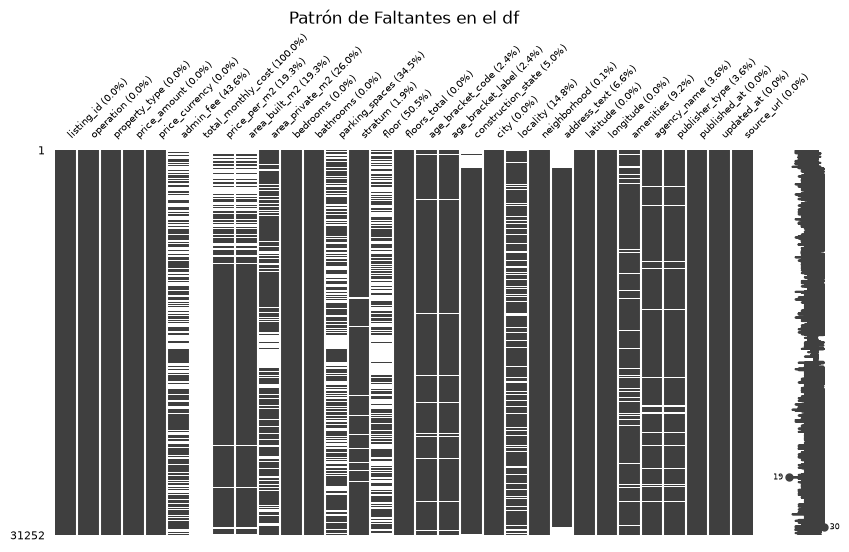

In [20]:
n_cols = len(df.columns)
ancho = max(10, int(n_cols * 0.35))
alto = 5

tamano_letra = max(6, 10 - n_cols // 10)

# Porcentaje de nulos por columna
pct_nulos = df.isnull().mean() * 100

try:
    ax = (
        msno.matrix(df, figsize=(ancho, alto), fontsize=tamano_letra)
        or plt.gca()
    )
    plt.title("Patrón de Faltantes en el df")

    if len(ax.get_xticks()) == n_cols:
        ax.set_xticks(range(n_cols))
        ax.set_xticklabels(
            [f"{c} ({p:.1f}%)" for c, p in zip(df.columns, pct_nulos)],
            rotation=45,
            ha="left",
            fontsize=tamano_letra,
        )

    plt.show()

except Exception:
    plt.figure(figsize=(ancho, alto))
    missing_pattern = df.isnull()

    plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

    plt.xticks(
        ticks=range(n_cols),
        labels=[
            f"{c} ({p:.1f}%)"
            for c, p in zip(missing_pattern.columns, pct_nulos)
        ],
        rotation=90,
        fontsize=tamano_letra,
        ha="center",
    )
    plt.yticks([])
    plt.title("Patrón de Faltantes (blanco = faltante)")
    plt.colorbar(label="1=Faltante, 0=Presente")

    plt.tight_layout()  # Evita que las etiquetas se corten abajo
    plt.show()

La base inicial contiene 31.252 observaciones y 31 variables. Algunas variables presentan una cantidad significativa de valores faltantes.

Entre las variables con mayor ausencia de información se encuentran `floor`, `admin_fee`, `parking_spaces`, `area_private_m2` y `area_built_m2`. Además, `total_monthly_cost` no contiene observaciones válidas, lo cual es coherente con que la base analizada corresponde a inmuebles en venta y esta variable está definida principalmente para publicaciones de arriendo.

# A correlation glance

d:\Externado\Cuarto semestre\bayesiana\proyecto_finca_raiz_colombia\utils\plotting.py:8491: UserWarning: Column 'total_monthly_cost' is numeric but has only 0 distinct value(s), so it is treated as categorical. Override with treat_as={'total_monthly_cost': 'numeric'} or the constructor's as_numeric=['total_monthly_cost'].
  kind = self.resolve_kind(frame[column], treat.get(column))
D:\Temp\ipykernel_22848\1200077013.py:1: UserWarning: corr_heatmap excluded 3 numeric-but-low-cardinality column(s) (total_monthly_cost, stratum, age_bracket_code): a correlation over a small integer code is usually misleading. Pass include_low_cardinality=True to keep them.
  plotter.corr_heatmap(


<Axes: >

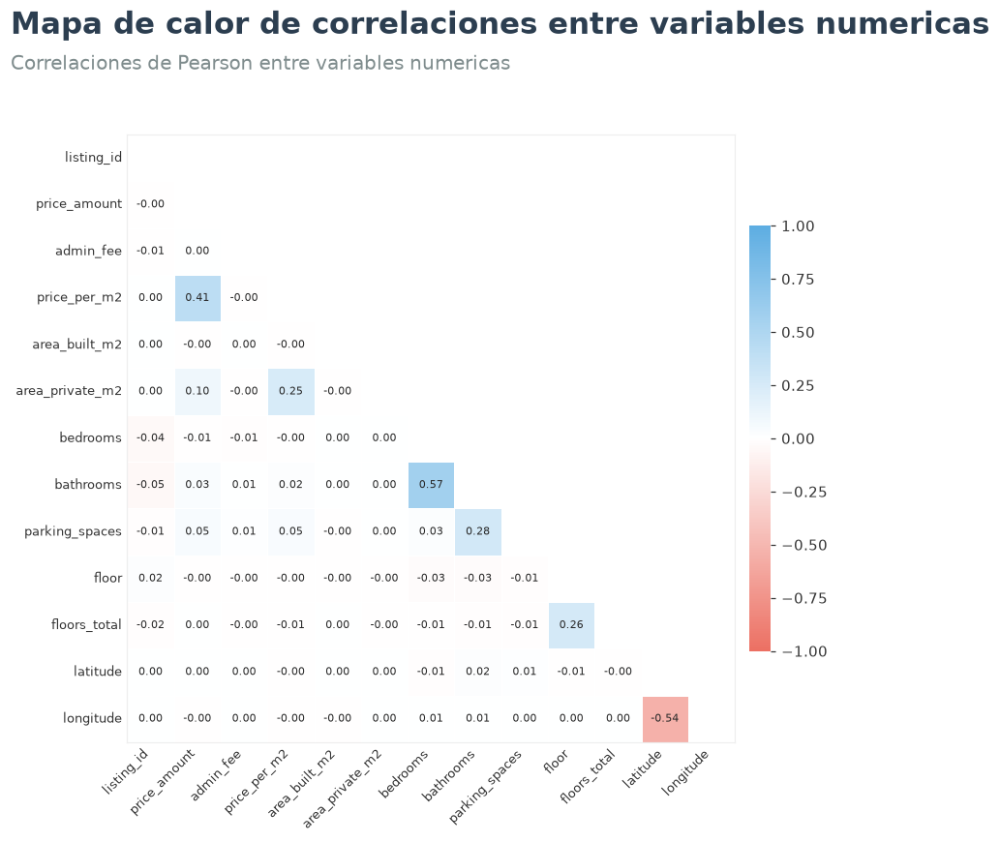

In [21]:
plotter.corr_heatmap(
    title="Mapa de calor de correlaciones entre variables numericas",
    subtitle="Correlaciones de Pearson entre variables numericas",
    annot=True,
)

D:\Temp\ipykernel_22848\4115540453.py:1: UserWarning: corr_heatmap excluded 3 numeric-but-low-cardinality column(s) (total_monthly_cost, stratum, age_bracket_code): a correlation over a small integer code is usually misleading. Pass include_low_cardinality=True to keep them.
  plotter.corr_heatmap(


<Axes: >

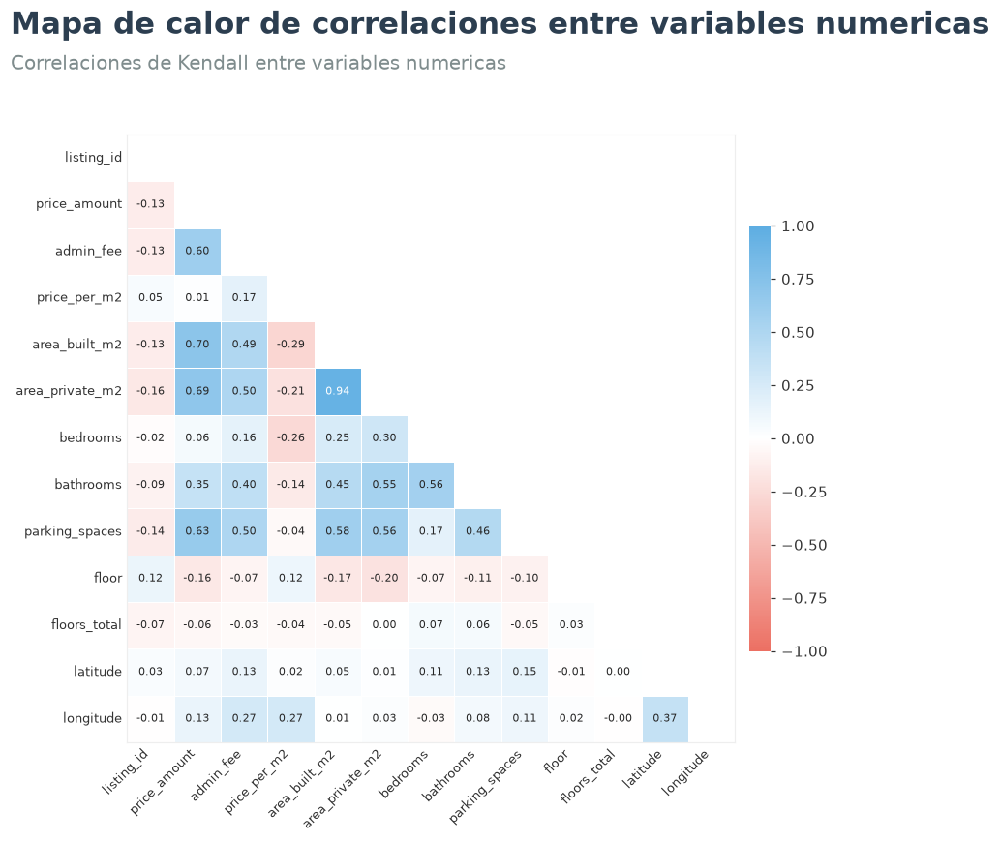

In [22]:
plotter.corr_heatmap(
    title="Mapa de calor de correlaciones entre variables numericas",
    subtitle="Correlaciones de Kendall entre variables numericas",
    method="kendall",
    annot=True,
)

Al comparar las matrices de Pearson y Kendall se observan diferencias en la magnitud de algunas asociaciones, particularmente en las relaciones con el precio. Que algunas correlaciones de Kendall sean superiores a las de Pearson no permite concluir por sí solo que exista una relación no lineal, pero esto se sospecha. 

En esta base inicial, la presencia de valores extremos e inconsistencias puede afectar de manera importante la correlación de Pearson, por lo que las relaciones se volverán a evaluar después de la limpieza.

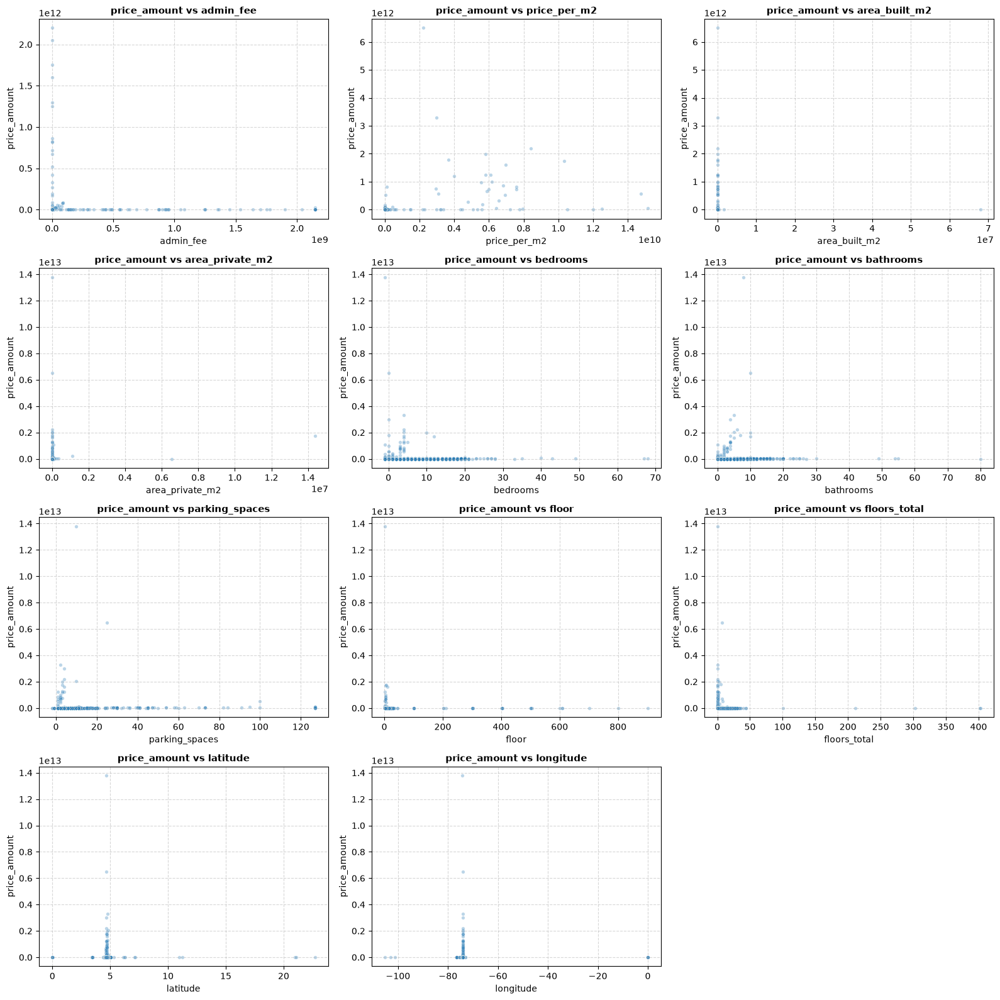

In [23]:
target = "price_amount"
predictors = [
    "admin_fee",
    "price_per_m2",
    "area_built_m2",
    "area_private_m2",
    "bedrooms",
    "bathrooms",
    "parking_spaces",
    "floor",
    "floors_total",
    "latitude",
    "longitude",
]

# 2. Configuración de la rejilla de subplots (3 columnas)
n_cols = 3
n_rows = math.ceil(len(predictors) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()  # Aplanar la matriz para iteración simple

# 3. Generación de los scatter plots
for i, col in enumerate(predictors):
    sns.scatterplot(
        data=df,
        x=col,
        y=target,
        ax=axes[i],
        alpha=0.3,  # Transparencia para mitigar overplotting
        s=15,  # Tamaño de puntos
        color="#1f77b4",
    )

    axes[i].set_title(f"{target} vs {col}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel(target)
    axes[i].grid(True, linestyle="--", alpha=0.5)

# 4. Eliminar subplots sobrantes en el grid
for i in range(len(predictors), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

En los gráficos de dispersión de la base sin limpiar, varias relaciones con el precio quedan visualmente dominadas por observaciones extremas, dificultando identificar patrones en la mayor parte de la muestra. 

Por esta razón, en esta etapa no es apropiado concluir que las asociaciones sean débiles únicamente a partir de estos gráficos. Las relaciones se revisarán nuevamente después del tratamiento de inconsistencias y valores atípicos. **Revise el gráfico nuevamente en data_cleaning.py**.

## Property locations on map

In [24]:
create_map(df)

# Descriptive statistics after cleaning

In [25]:
df = pd.read_csv("../data/datos_inmobiliarios_clean.csv")

In [26]:
df.describe()

,price_amount,admin_fee,price_per_m2,area_built_m2,area_private_m2,bedrooms,bathrooms,parking_spaces,stratum,floor,age_bracket_code,latitude,longitude,log_price_amount
count,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00,20253.00
mean,913182971.63,646413.01,6396014.75,161.40,160.07,3.38,2.87,1.88,4.22,4.21,3.51,4.69,-74.07,20.36
std,701066231.11,588285.05,2558911.12,128.06,131.85,2.01,1.52,1.73,1.23,3.64,1.41,0.05,0.04,0.75
min,87703000.00,1.00,833333.33,14.00,11.94,1.00,1.00,1.00,1.00,1.00,0.00,4.47,-74.24,18.29
25%,380000000.00,212580.04,4666666.67,61.13,60.00,2.00,2.00,1.00,3.00,2.00,2.00,4.65,-74.09,19.76
50%,700000000.00,445000.00,5997283.36,120.00,117.20,3.00,3.00,2.00,4.00,3.00,4.00,4.70,-74.07,20.37
75%,1220000000.00,889400.00,7777777.78,230.00,224.00,4.00,4.00,2.00,5.00,5.00,5.00,4.72,-74.05,20.92
max,4000000000.00,3324488.02,17541666.67,805.80,786.00,33.00,20.00,127.00,6.00,35.00,5.00,5.03,-74.01,22.11


Después del proceso de limpieza, la base queda conformada por **20.253 observaciones** y los estadísticos descriptivos muestran valores considerablemente más consistentes que en la exploración inicial.

El precio de los inmuebles presenta una media aproximada de $913 millones y una mediana de $700 millones. Aunque la media continúa siendo superior a la mediana, lo que indica que la distribución conserva cierta asimetría hacia la derecha, los valores extremos se redujeron considerablemente: el precio máximo es ahora de $4.000 millones.

El área construida presenta una mediana de 120 m² y un promedio de aproximadamente 161 m², mientras que el área privada tiene una mediana cercana a 117 m². En ambas variables la media sigue siendo mayor que la mediana, lo que sugiere la presencia de inmuebles de gran tamaño que desplazan la distribución hacia valores superiores.